In [1]:
from pathlib import Path
from time import perf_counter
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

N, Q, Y = 11, 1, 26
VARIANT = 1 + (17 * N + 7 * Q + Y) % 20
N_ITEMS = 30
DATA_SEED = 10000 * Y + 100 * N + Q
SEEDS = list(range(N * 1000 + 1, N * 1000 + 21))
POP_SIZE, ELITE, GENERATIONS = 100, 2, 300
TOURNAMENT_SIZE, P_CROSSOVER, P_MUTATION = 3, 0.9, 1 / N_ITEMS
BUDGET = POP_SIZE + GENERATIONS * (POP_SIZE - ELITE)
CHECKPOINTS = POP_SIZE + np.arange(GENERATIONS + 1) * (POP_SIZE - ELITE)
CONFIGS = {"A": ("repair", "one_point"), "B": ("penalty", "one_point"),
           "C": ("repair", "uniform"), "RS": ("random", None)}
LABELS = {"A": "A: ремонт, одноточечный", "B": "B: штраф, одноточечный",
          "C": "C: ремонт, равномерный", "RS": "RS: случайный поиск + ремонт"}
OUT = Path("results")
OUT.mkdir(exist_ok=True)
assert VARIANT == 1 and N_ITEMS >= 30
assert 1 <= ELITE < POP_SIZE and GENERATIONS > 0
assert 0 <= P_CROSSOVER <= 1 and 0 <= P_MUTATION <= 1
assert len(SEEDS) >= 20 and len(SEEDS) == len(set(SEEDS))

In [2]:
rng_data = np.random.default_rng(DATA_SEED)
DATA = np.column_stack([rng_data.integers(1, 31, N_ITEMS),
                        rng_data.integers(1, 21, N_ITEMS),
                        rng_data.integers(10, 101, N_ITEMS)])
LIMITS = (0.35 * DATA[:, :2].sum(axis=0)).astype(int)
PENALTY = int(DATA[:, 2].sum() + 1)
DENSITY = DATA[:, 2] / (DATA[:, :2] / LIMITS).sum(axis=1)
REMOVE_ORDER = np.argsort(DENSITY, kind="stable")
items = pd.DataFrame(DATA, columns=["mass", "volume", "value"])
items.insert(0, "item", np.arange(1, N_ITEMS + 1))
items.to_csv(OUT / "items.csv", index=False)
print(f"Вариант {VARIANT}; предметов: {N_ITEMS}; лимиты: {LIMITS.tolist()}")


def feasible(population):
    return np.all(population @ DATA[:, :2] <= LIMITS, axis=1)


def repair(population):
    repaired = population.astype(bool, copy=True)
    loads = repaired @ DATA[:, :2]
    for item in REMOVE_ORDER:
        remove = np.any(loads > LIMITS, axis=1) & repaired[:, item]
        repaired[remove, item] = False
        loads[remove] -= DATA[item, :2]
    return repaired


def evaluate(population):
    totals = population @ DATA
    excess = np.maximum(totals[:, :2] - LIMITS, 0).sum(axis=1)
    return totals[:, 2] - PENALTY * excess, totals, excess == 0

Вариант 1; предметов: 30; лимиты: [184, 117]


In [3]:
def tournament(population, scores, count, rng):
    candidates = rng.integers(len(population), size=(count, TOURNAMENT_SIZE))
    winners = candidates[np.arange(count), np.argmax(scores[candidates], axis=1)]
    return population[winners]


def crossover(parents1, parents2, kind, rng):
    count = len(parents1)
    if kind == "one_point":
        cuts = rng.integers(1, N_ITEMS, size=(count, 1))
        mask = np.arange(N_ITEMS) < cuts
    elif kind == "uniform":
        mask = rng.random(parents1.shape) < 0.5
    else:
        raise ValueError("Неизвестный кроссовер")
    children = np.where(mask, parents1, parents2)
    skipped = rng.random(count) >= P_CROSSOVER
    children[skipped] = parents1[skipped]
    return children


def mutate(children, rng):
    return children ^ (rng.random(children.shape) < P_MUTATION)

In [4]:
def genetic_algorithm(seed, handling="repair", cross_kind="one_point"):
    assert handling in ("repair", "penalty")
    started = perf_counter()
    rng = np.random.default_rng(seed)
    population = rng.random((POP_SIZE, N_ITEMS)) < 0.5
    raw_valid = int(feasible(population).sum())
    population = repair(population)  # Общая допустимая инициализация для A, B, C.
    scores, totals, valid = evaluate(population)
    evaluations, valid_count = POP_SIZE, int(valid.sum())
    k = int(np.argmax(scores))
    best, best_totals = population[k].copy(), totals[k].copy()
    history, valid_history = [int(best_totals[2])], [float(valid.mean())]
    for _ in range(GENERATIONS):
        elite = np.argsort(-scores, kind="stable")[:ELITE]
        count = POP_SIZE - ELITE
        parents = tournament(population, scores, 2 * count, rng)
        children = mutate(crossover(parents[:count], parents[count:], cross_kind, rng), rng)
        raw_valid += int(feasible(children).sum())
        if handling == "repair":
            children = repair(children)
        child_scores, child_totals, child_valid = evaluate(children)
        evaluations += count
        valid_count += int(child_valid.sum())
        k = int(np.argmax(np.where(child_valid, child_totals[:, 2], -1)))
        if child_valid[k] and child_totals[k, 2] > best_totals[2]:
            best, best_totals = children[k].copy(), child_totals[k].copy()
        population = np.vstack([population[elite], children])
        scores = np.r_[scores[elite], child_scores]
        valid = np.r_[valid[elite], child_valid]
        history.append(int(best_totals[2]))
        valid_history.append(float(valid.mean()))
    record = dict(seed=seed, value=int(best_totals[2]), mass=int(best_totals[0]),
                  volume=int(best_totals[1]), evaluations=evaluations,
                  raw_feasible=raw_valid / evaluations, evaluated_feasible=valid_count / evaluations,
                  final_feasible=float(valid.mean()), seconds=perf_counter() - started,
                  bits="".join(best.astype(int).astype(str)))
    return record, np.array(history), np.array(valid_history)

In [5]:
def random_search(seed):
    started = perf_counter()
    rng = np.random.default_rng(seed)
    best_value, evaluations, raw_valid = -1, 0, 0
    history = []
    for checkpoint in CHECKPOINTS:
        population = rng.random((int(checkpoint) - evaluations, N_ITEMS)) < 0.5
        raw_valid += int(feasible(population).sum())
        population = repair(population)
        _, totals, valid = evaluate(population)
        k = int(np.argmax(totals[:, 2]))
        if totals[k, 2] > best_value:
            best, best_totals = population[k].copy(), totals[k].copy()
            best_value = int(best_totals[2])
        evaluations += len(population)
        history.append(best_value)
    record = dict(seed=seed, value=best_value, mass=int(best_totals[0]),
                  volume=int(best_totals[1]), evaluations=evaluations,
                  raw_feasible=raw_valid / evaluations, evaluated_feasible=1.0,
                  final_feasible=1.0, seconds=perf_counter() - started,
                  bits="".join(best.astype(int).astype(str)))
    return record, np.array(history), np.ones(len(history))


def greedy_solution():
    chosen, loads = np.zeros(N_ITEMS, dtype=bool), np.zeros(2, dtype=int)
    for item in REMOVE_ORDER[::-1]:
        if np.all(loads + DATA[item, :2] <= LIMITS):
            chosen[item] = True
            loads += DATA[item, :2]
    return chosen

In [6]:
example_sets = [[], [1, 2, 3, 4, 5], [3, 6, 9, 11, 15, 16, 20, 22],
                [1, 2, 4, 12, 14, 18, 25, 26]]
example_bits = np.zeros((4, N_ITEMS), dtype=bool)
for i, selected in enumerate(example_sets):
    example_bits[i, np.array(selected, dtype=int) - 1] = True
_, example_totals, example_valid = evaluate(example_bits)
assert example_valid.tolist() == [True, True, False, False]
assert example_totals[2, 0] > LIMITS[0] and example_totals[2, 1] <= LIMITS[1]
assert example_totals[3, 0] <= LIMITS[0] and example_totals[3, 1] > LIMITS[1]
examples = pd.DataFrame(example_totals, columns=["mass", "volume", "value"])
examples.insert(0, "items", [" ".join(map(str, x)) or "пустой набор" for x in example_sets])
examples["feasible"] = example_valid
examples.to_csv(OUT / "examples.csv", index=False)
test_rng = np.random.default_rng(123)
test_population = test_rng.random((100, N_ITEMS)) < 0.5
fixed = repair(test_population)
assert feasible(fixed).all() and np.array_equal(repair(fixed), fixed)
assert np.array_equal(repair(example_bits[:2]), example_bits[:2])
assert feasible(repair(np.ones((1, N_ITEMS), dtype=bool))).all()
for kind in ("one_point", "uniform"):
    assert np.array_equal(crossover(fixed, fixed, kind, test_rng), fixed)
    child = mutate(crossover(fixed, fixed[::-1], kind, test_rng), test_rng)
    assert child.shape == fixed.shape and child.dtype == bool
scores, _, ok = evaluate(test_population)
assert (scores[~ok] < 0).all() and (scores[ok] >= 0).all()
display(examples)

,items,mass,volume,value,feasible
0,пустой набор,0,0,0,True
1,1 2 3 4 5,65,72,270,True
2,3 6 9 11 15 16 20 22,195,35,339,False
3,1 2 4 12 14 18 25 26,57,122,484,False


In [7]:
records, histories, feasibility_histories, traces = [], {}, {}, []
for method, (handling, kind) in CONFIGS.items():
    histories[method], feasibility_histories[method] = [], []
    for seed in SEEDS:
        result, history, valid_history = (random_search(seed) if method == "RS"
                                          else genetic_algorithm(seed, handling, kind))
        result["method"] = method
        records.append(result)
        histories[method].append(history)
        feasibility_histories[method].append(valid_history)
        traces.append(pd.DataFrame({"method": method, "seed": seed,
                      "generation": np.arange(GENERATIONS + 1), "evaluations": CHECKPOINTS,
                      "best_value": history, "population_feasible": valid_history}))
    histories[method] = np.array(histories[method])
    feasibility_histories[method] = np.array(feasibility_histories[method])
    print(f"{LABELS[method]}: завершено {len(SEEDS)} запусков")
runs = pd.DataFrame(records)
convergence = pd.concat(traces, ignore_index=True)
runs.to_csv(OUT / "runs.csv", index=False)
convergence.to_csv(OUT / "convergence.csv", index=False)

A: ремонт, одноточечный: завершено 20 запусков


B: штраф, одноточечный: завершено 20 запусков


C: ремонт, равномерный: завершено 20 запусков


RS: случайный поиск + ремонт: завершено 20 запусков


In [8]:
summary = runs.groupby("method", sort=False).agg(
    best=("value", "max"), mean=("value", "mean"), median=("value", "median"),
    std=("value", "std"), worst=("value", "min"), raw_feasible=("raw_feasible", "mean"),
    evaluated_feasible=("evaluated_feasible", "mean"), final_feasible=("final_feasible", "mean"),
    mean_seconds=("seconds", "mean"))
summary.to_csv(OUT / "summary.csv")
display(summary.round(4))
parameters = dict(N=N, Q=Q, Y=Y, variant=VARIANT, n_items=N_ITEMS, data_seed=DATA_SEED,
                  limits=LIMITS.tolist(), capacity_fraction=0.35, seeds=SEEDS,
                  population=POP_SIZE, elite=ELITE, generations=GENERATIONS,
                  tournament_size=TOURNAMENT_SIZE, p_crossover=P_CROSSOVER,
                  p_mutation=P_MUTATION, penalty=PENALTY, budget=BUDGET, configs=CONFIGS,
                  python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__)
(OUT / "parameters.json").write_text(json.dumps(parameters, ensure_ascii=False, indent=2), encoding="utf-8")

,best,mean,median,std,worst,raw_feasible,evaluated_feasible,final_feasible,mean_seconds
method,,,,,,,,,
A,807,806.9,807.0,0.4472,805,0.5591,1.0000,1.000,0.1444
B,807,804.9,806.0,2.4473,799,0.5891,0.5924,0.594,0.0370
C,807,807.0,807.0,0.0000,807,0.5530,1.0000,1.000,0.1574
RS,803,797.4,800.0,5.6699,786,0.0320,1.0000,1.000,0.1224


853

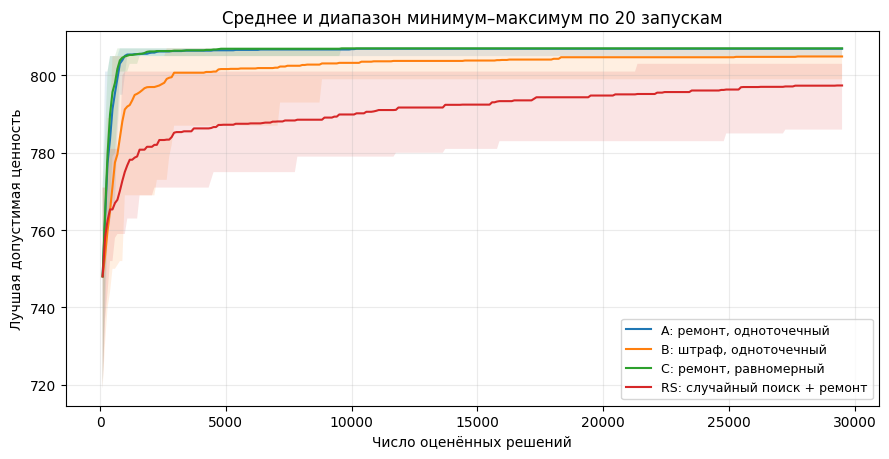

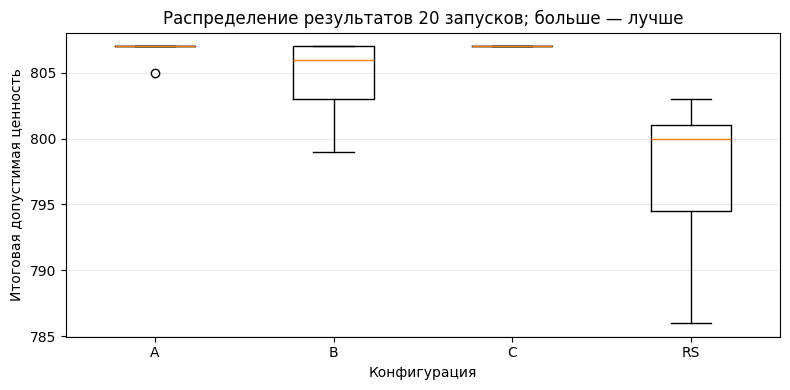

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.7))
for method, h in histories.items():
    ax.plot(CHECKPOINTS, h.mean(axis=0), label=LABELS[method])
    ax.fill_between(CHECKPOINTS, h.min(axis=0), h.max(axis=0), alpha=0.12)
ax.set(xlabel="Число оценённых решений", ylabel="Лучшая допустимая ценность",
       title="Среднее и диапазон минимум–максимум по 20 запускам")
ax.grid(alpha=0.25)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "convergence.png", dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([runs.loc[runs.method == k, "value"] for k in CONFIGS])
ax.set_xticks(np.arange(1, len(CONFIGS) + 1), list(CONFIGS))
ax.set(xlabel="Конфигурация", ylabel="Итоговая допустимая ценность",
       title="Распределение результатов 20 запусков; больше — лучше")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "distributions.png", dpi=180)
plt.show()

,item,mass,volume,value
0,1,8,19,77
9,10,17,8,62
10,11,20,2,53
13,14,6,8,34
15,16,27,6,89
17,18,12,16,97
21,22,29,3,42
23,24,25,18,99
24,25,1,19,92
28,29,12,6,92


Лучший ГА: A, seed=11001; ценность=807, масса=179, объём=117
Жадный ориентир: масса, объём, ценность = [169, 116, 801]


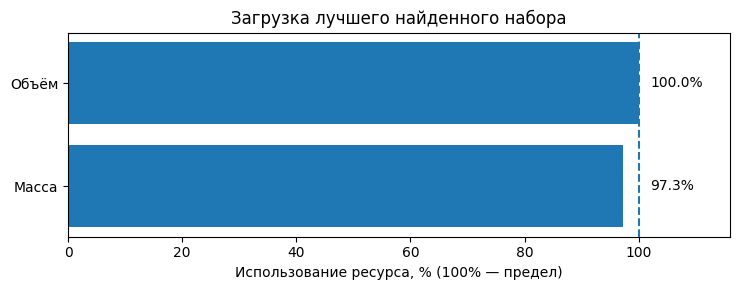

In [10]:
best_row = runs.loc[runs.loc[runs.method != "RS", "value"].idxmax()]
best_bits = np.array(list(best_row.bits), dtype=int).astype(bool)
best_items = items.loc[best_bits].copy()
best_items.to_csv(OUT / "best_items.csv", index=False)
display(best_items)
greedy = greedy_solution()
greedy_totals = greedy @ DATA
print(f"Лучший ГА: {best_row.method}, seed={best_row.seed}; ценность={best_row.value}, "
      f"масса={best_row.mass}, объём={best_row.volume}")
print(f"Жадный ориентир: масса, объём, ценность = {greedy_totals.tolist()}")
(OUT / "best_solution.json").write_text(json.dumps({
    "method": best_row.method, "seed": int(best_row.seed), "items": best_items.item.tolist(),
    "mass": int(best_row.mass), "volume": int(best_row.volume), "value": int(best_row.value),
    "greedy_items": (np.flatnonzero(greedy) + 1).tolist(),
    "greedy_totals": greedy_totals.tolist()}, ensure_ascii=False, indent=2), encoding="utf-8")
fig, ax = plt.subplots(figsize=(7.5, 3))
usage = best_bits @ DATA[:, :2] / LIMITS * 100
ax.barh(["Масса", "Объём"], usage)
ax.axvline(100, linestyle="--", label="Допустимый предел")
ax.set(xlabel="Использование ресурса, % (100% — предел)", xlim=(0, 116), title="Загрузка лучшего найденного набора")
for i, value in enumerate(usage):
    ax.text(102, i, f"{value:.1f}%", va="center")
fig.tight_layout()
fig.savefig(OUT / "best_load.png", dpi=180)
plt.show()

In [11]:
assert len(runs) == 4 * len(SEEDS) and (runs.evaluations == BUDGET).all()
assert runs.groupby("method").size().eq(20).all()
for row in runs.itertuples():
    bits = np.array(list(row.bits), dtype=int)
    totals = bits @ DATA
    assert len(bits) == N_ITEMS and np.isin(bits, [0, 1]).all()
    assert np.all(totals[:2] <= LIMITS)
    assert totals.tolist() == [row.mass, row.volume, row.value]
for method, h in histories.items():
    assert h.shape == (len(SEEDS), GENERATIONS + 1) and np.all(np.diff(h, axis=1) >= 0)
    assert np.array_equal(h[:, -1], runs.loc[runs.method == method, "value"].to_numpy())
handling, kind = CONFIGS[best_row.method]
repeated, repeated_history, _ = genetic_algorithm(int(best_row.seed), handling, kind)
assert repeated["bits"] == best_row.bits and repeated["value"] == best_row.value
assert np.array_equal(repeated_history, histories[best_row.method][SEEDS.index(int(best_row.seed))])
print("Проверены 80 итоговых решений, бюджет, сходимость, операторы и воспроизводимость лучшего запуска.")

Проверены 80 итоговых решений, бюджет, сходимость, операторы и воспроизводимость лучшего запуска.
